In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path
import seaborn as sns
from pathlib import Path

from utils import plot_spatial_kernel_hex
from utils.plotting import vector_to_kernel, plot_stats
from utils.spatial_RF import compute_kernel, all_input_kernels
from matplotlib.colors import TwoSlopeNorm,  Normalize

from utils import stats_ctype_pair
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 300

In [2]:
data_dir = Path('results/connectome')

edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar_T4T5norm.feather')
nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar_T4T5norm.feather')

# edges       = pd.read_feather(data_dir / 'edgelist_OL_columnar.feather')
# nodes_df    = pd.read_feather(data_dir / 'nodes_OL_columnar.feather')

print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


In [3]:
T5b = "T5b"
T4b = "T4b"
RADIUS    = 2
THRESHOLD = 1.0
MEAN_THRESH = 0.0

# Choose what each matrix entry should contain
VALUE_COL = "count"   # or "count" 



In [4]:
meanT5b, fullT5b, T5binputs = all_input_kernels(T5b, edges, 
                                                radius= RADIUS, value_col=VALUE_COL)

meanT4b, fullT4b, T4binputs = all_input_kernels(T4b, edges, 
                                                radius= RADIUS, value_col=VALUE_COL)

Strong input types:  ['Tm2', 'Tm9', 'CT1', 'Tm1', 'Tm4', 'T5b']
Strong input types:  ['Mi1', 'Mi9', 'Mi4', 'CT1', 'T4b', 'C3']


In [5]:
fullT5b

{'Tm4':          post  target_p  target_q post_side  dp  dq  count  signed_count  \
 0       98389       6.0     -10.0     right  -2  -2    0.0           0.0   
 1       98389       6.0     -10.0     right  -2  -1    0.0           0.0   
 2       98389       6.0     -10.0     right  -2   0    0.0           0.0   
 3       98389       6.0     -10.0     right  -1  -2    0.0           0.0   
 4       98389       6.0     -10.0     right  -1  -1   11.0          11.0   
 ...       ...       ...       ...       ...  ..  ..    ...           ...   
 16411  160169     -14.0      -3.0     right   1   1    0.0           0.0   
 16412  160169     -14.0      -3.0     right   1   2    0.0           0.0   
 16413  160169     -14.0      -3.0     right   2   0    0.0           0.0   
 16414  160169     -14.0      -3.0     right   2   1    0.0           0.0   
 16415  160169     -14.0      -3.0     right   2   2    0.0           0.0   
 
        source_p  source_q pre_cell_type post_cell_type  
 0       

In [5]:
cell_dfT5, hist_df_T5, sim_dfT5, summary_dfT5, kernel_mapsT5 = stats_ctype_pair(fullT5b, 
                                                                    T5binputs, 
                                                                    post_type=T5b)

cell_dfT4, hist_df_T4, sim_dfT4, summary_dfT4, kernel_mapsT4 = stats_ctype_pair(fullT4b, 
                                                                    T4binputs, 
                                                                    post_type=T4b)

/tmp/ipykernel_21548/4017689079.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(
/tmp/ipykernel_21548/4017689079.py:37: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(


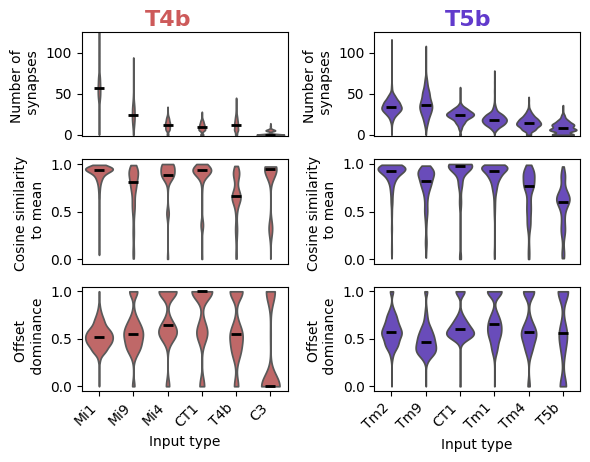

In [6]:
total_input_df_T5 = hist_df_T5.query("metric == 'total_input'")
cosine_sim_df_T5 = hist_df_T5.query("metric == 'cosine_similarity_to_mean'")
dominance_df_T5 = hist_df_T5.query("metric == 'dominance'")

total_input_df_T4 = hist_df_T4.query("metric == 'total_input'")
cosine_sim_df_T4 = hist_df_T4.query("metric == 'cosine_similarity_to_mean'")
dominance_df_T4 = hist_df_T4.query("metric == 'dominance'")


fig, axes = plt.subplots(3,2, figsize=(6,4.5))

colorT4 = "#CD5A5A"
colorT5 = "#613ACC"


fig.text(x=0.75,y=0.98, s=f"{T5b}", fontsize=16, weight='bold', color=colorT5)
fig.text(x=0.25,y=0.98, s=f"{T4b}", fontsize=16, weight='bold', color=colorT4)


plot_stats(total_input_df_T5, axes[0,1], colorT5, "Number of \n synapses")
plot_stats(cosine_sim_df_T5, axes[1,1], colorT5, "Cosine similarity \n to mean")
plot_stats(dominance_df_T5, axes[2,1], colorT5, "Offset \n dominance")

plot_stats(total_input_df_T4, axes[0,0], colorT4, "Number of \n synapses")
plot_stats(cosine_sim_df_T4, axes[1,0], colorT4, "Cosine similarity \n to mean")
plot_stats(dominance_df_T4, axes[2,0], colorT4, "Offset \n dominance")

# Hide x-axis labels/ticks for first two rows
for ax in axes[:2, :].ravel():
    ax.set_xlabel("")
    ax.set_xticklabels([])
    ax.tick_params(axis="x", length=0)

# Keep x-axis labels only on bottom row
for ax in axes[2, :]:
    ax.set_xlabel("Input type")
    ax.set_xticklabels(
        ax.get_xticklabels(),
        rotation=45,
        ha="right",
    )

axes[0, 0].set_ylim(-2, 125)
axes[0, 1].set_ylim(-2, 125)

fig.tight_layout()

## Plot results for 1 pair

In [9]:
input_types= T5binputs
kernel_maps = kernel_mapsT5
POST_TYPE   = 'T5B'

/tmp/ipykernel_21548/596153575.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


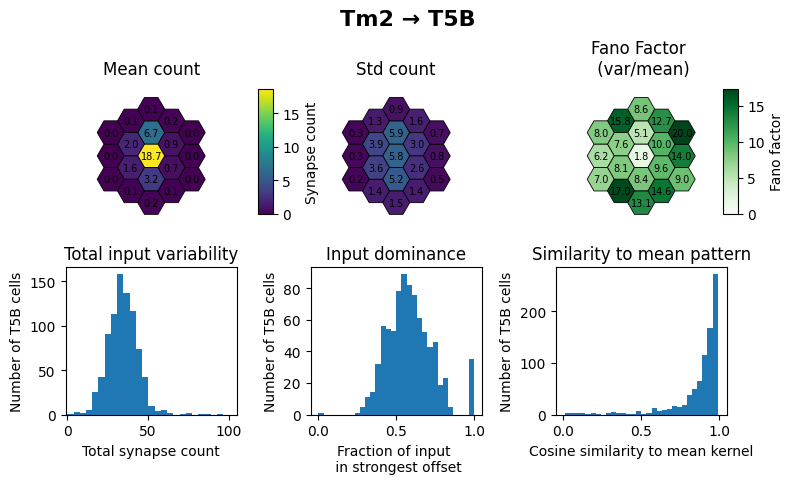

/tmp/ipykernel_21548/596153575.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


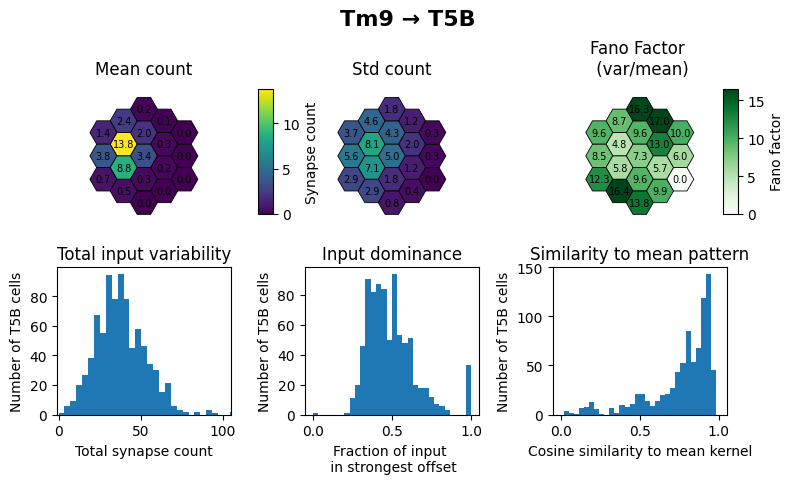

/tmp/ipykernel_21548/596153575.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


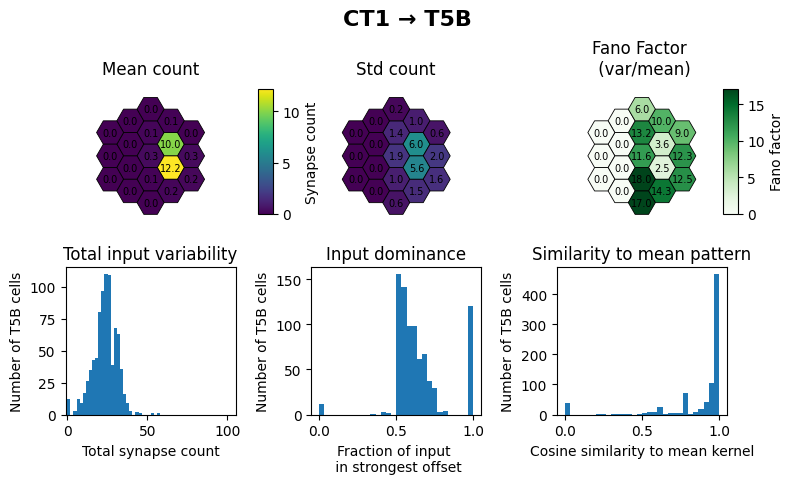

/tmp/ipykernel_21548/596153575.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


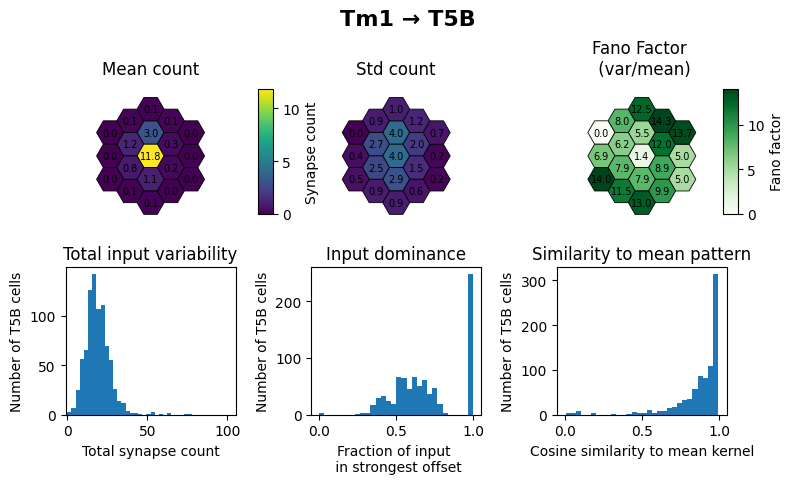

/tmp/ipykernel_21548/596153575.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


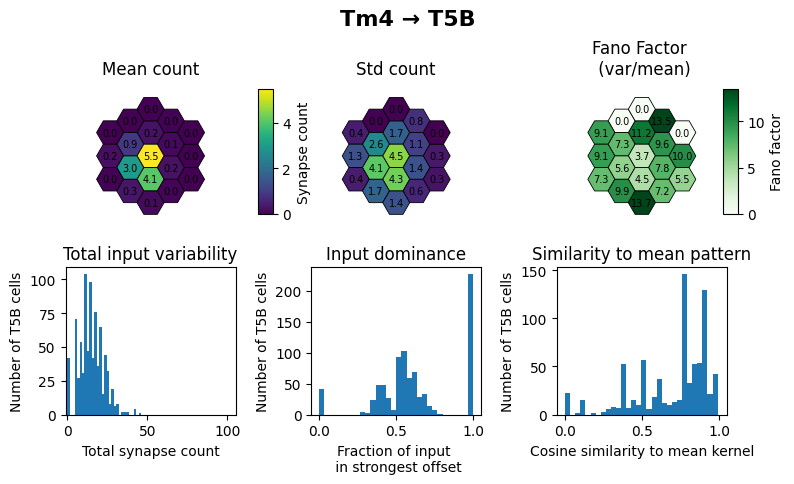

/tmp/ipykernel_21548/596153575.py:163: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


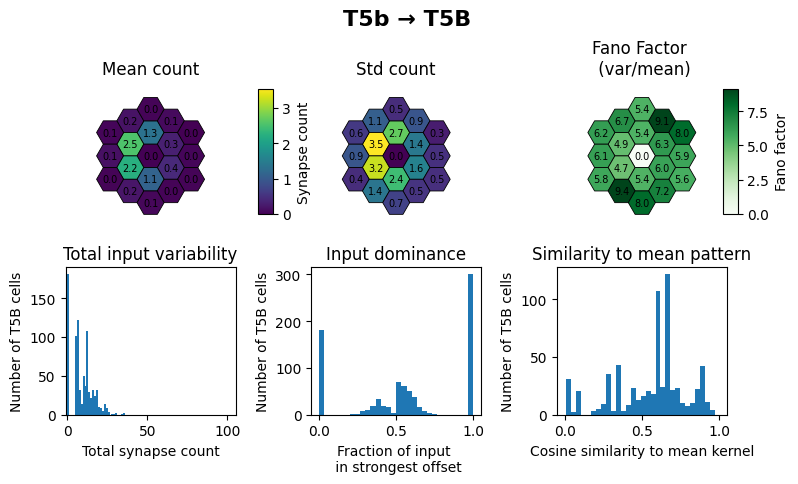

In [10]:
# ============================================================
# Plot input kernel summaries
# ============================================================

for pre_type in input_types:
    data = kernel_maps[pre_type]

    mean_vec = data["Mean count"]
    std_vec = data["Std count"]
    fano_vec = data["Fano Factor \n (var/mean)"]

    total_input = data["total_input"]
    dominance = data["dominance"]
    cosine_to_mean = data["cosine_to_mean"]

    maps = {
        "Mean count": mean_vec,
        "Std count": std_vec,
        "Fano Factor \n (var/mean)": fano_vec,
    }

    # ------------------------------------------------------------
    # Color normalization
    # ------------------------------------------------------------
    count_vmax = max(mean_vec.max(), std_vec.max())

    count_norm = Normalize(
        vmin=0,
        vmax=count_vmax,
    )

    fano_vmax = np.nanpercentile(fano_vec, 95)

    if np.isnan(fano_vmax) or fano_vmax <= 0:
        fano_vmax = 1

    fano_norm = Normalize(
        vmin=0,
        vmax=fano_vmax,
    )

    # ------------------------------------------------------------
    # Figure
    # ------------------------------------------------------------
    fig, axes = plt.subplots(
        2,
        3,
        figsize=(7.5, 5),
    )

    fig.suptitle(
        f"{pre_type} → {POST_TYPE}",
        fontsize=16,
        weight="bold",
        x=0.55,
        y=0.96,
    )

    axes_kernel = axes[0, :]
    ax_hist = axes[1, :]

    # ------------------------------------------------------------
    # Spatial kernel plots
    # ------------------------------------------------------------
    for ax, (title, vec) in zip(axes_kernel, maps.items()):
        ax.axis("off")

        kernel = vector_to_kernel(
            vec,
            value_name="value",
        )

        if "Fano" in title:
            this_norm = fano_norm
            this_cmap = "Greens"
        else:
            this_norm = count_norm
            this_cmap = "viridis"

        plot_spatial_kernel_hex(
            kernel,
            ax=ax,
            value_col="value",
            norm=this_norm,
            cmap=this_cmap,
            radius=RADIUS,
            add_colorbar=False,
            emphasize_center=False,
        )

        ax.set_title(title)

    # ------------------------------------------------------------
    # Count colorbar for mean/std
    # ------------------------------------------------------------
    sm_count = plt.cm.ScalarMappable(
        norm=count_norm,
        cmap=plt.get_cmap("viridis"),
    )

    sm_count.set_array([])

    cax1 = fig.add_axes([0.35, 0.55, 0.02, 0.25])

    fig.colorbar(
        sm_count,
        cax=cax1,
        label="Synapse count",
    )

    # ------------------------------------------------------------
    # Fano colorbar
    # ------------------------------------------------------------
    sm_fano = plt.cm.ScalarMappable(
        norm=fano_norm,
        cmap=plt.get_cmap("Greens"),
    )

    sm_fano.set_array([])

    cax2 = fig.add_axes([0.97, 0.55, 0.02, 0.25])

    fig.colorbar(
        sm_fano,
        cax=cax2,
        label="Fano factor",
    )

    # ------------------------------------------------------------
    # Histograms
    # ------------------------------------------------------------

    ax_hist[0].hist(
        total_input,
        bins=30,
    )

    ax_hist[0].set_xlabel("Total synapse count")
    ax_hist[0].set_ylabel(f"Number of {POST_TYPE} cells")
    ax_hist[0].set_title("Total input variability")
    ax_hist[0].set_xlim(-1, 105)

    ax_hist[1].hist(
        dominance,
        bins=30,
    )

    ax_hist[1].set_xlabel("Fraction of input \n in strongest offset")
    ax_hist[1].set_ylabel(f"Number of {POST_TYPE} cells")
    ax_hist[1].set_title("Input dominance")
    ax_hist[1].set_xlim(-0.05, 1.05)

    ax_hist[2].hist(
        cosine_to_mean,
        bins=30,
    )

    ax_hist[2].set_xlabel("Cosine similarity to mean kernel")
    ax_hist[2].set_ylabel(f"Number of {POST_TYPE} cells")
    ax_hist[2].set_title("Similarity to mean pattern")
    ax_hist[2].set_xlim(-0.05, 1.05)

    fig.tight_layout()

    plt.show()